In [1]:
# =========================================================================
#  DEPENDENCIAS — EJECUTAR ESTA CELDA PRIMERO
# -------------------------------------------------------------------------
#  Revisa paquete por paquete e instala UNICAMENTE los que falten.
#  Respecto al notebook 01 se agrega `optuna` para la busqueda de
#  hiperparametros.
# =========================================================================
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

REQUISITOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "psutil": "psutil",
    "joblib": "joblib",
    "torch": "torch",
    "optuna": "optuna",                   # busqueda de hiperparametros
}

faltantes = [pip_name for modulo, pip_name in REQUISITOS.items()
             if importlib.util.find_spec(modulo) is None]

if faltantes:
    print(f"Faltan {len(faltantes)} paquete(s): {', '.join(faltantes)}")
    print("Instalando (puede tardar un par de minutos)...\n")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
    print("\nInstalacion terminada. Si el entorno pide REINICIAR el kernel,")
    print("reinicia y vuelve a ejecutar desde esta celda.")
else:
    print("Todas las dependencias ya estaban instaladas: no se descargo nada.")

print("\nVersiones en uso")
print("-" * 36)
for pip_name in REQUISITOS.values():
    try:
        print(f"  {pip_name:<18} {metadata.version(pip_name)}")
    except metadata.PackageNotFoundError:
        print(f"  {pip_name:<18} (no detectada)")

Todas las dependencias ya estaban instaladas: no se descargo nada.

Versiones en uso
------------------------------------
  numpy              2.3.5
  pandas             2.3.3
  pyarrow            26.0.1
  scikit-learn       1.9.1
  matplotlib         3.10.0
  psutil             5.9.8
  joblib             1.6.0
  torch              2.15.0
  optuna             5.1.0


# Laboratorio 1 — Fase B: Feature Engineering, Optuna y Modelos Base
### Opción B: Predicción Científica — *HIGGS Boson Dataset*

**Curso:** Fundamentos de Aprendizaje Profundo y Aplicaciones — 2-2026
**Grupo:** 6 · **Integrante:** Cristopher Angulo Ahumada (trabajo individual)

---

## 1. Antecedentes

El notebook `01_EDA_y_Preprocessing.ipynb` estableció tres hallazgos que condicionan el diseño de
esta fase:

1. **Ninguna variable discrimina de forma aislada.** Las 21 variables cinemáticas de bajo nivel
   presentan distribuciones prácticamente superpuestas entre señal y fondo; la información
   discriminante reside en las interacciones entre ellas.
2. **Existe colinealidad fuerte entre las masas invariantes** (`m_wwbb`–`m_wbb` = 0,896), lo que
   obliga a regularizar de forma explícita.
3. **El problema no es separable linealmente ni por agrupamiento.** Se requieren 20 de 28
   componentes principales para explicar el 90 % de la varianza, y el ARI de K-Means frente a la
   etiqueta real es de 0,0085.

## 2. Contenido

| Etapa | Descripción |
|---|---|
| **B.0** | **Feature engineering**: construcción de 23 variables derivadas a partir de la cinemática del evento |
| **B.1** | Particionado y escalado del conjunto ampliado, sin *data leakage* |
| **B.2** | Arquitectura FFNN con Batch Normalization, Dropout e inicialización He/Xavier |
| **B.3** | Motor de entrenamiento: AdamW, Early Stopping y checkpoints en Google Drive |
| **B.4** | **Búsqueda progresiva de hiperparámetros con Optuna** sobre el 20 % de los datos |
| **B.5** | Entrenamiento de los **modelos base** con muestreo Bootstrap sobre el 100 % de los datos |
| **B.6** | Curvas de entrenamiento y evaluación individual |

Los modelos base entrenados en esta fase constituyen el insumo del notebook
`03_Stacking_Ensemble_Final.ipynb`.

## 3. Cantidad de modelos base

El enunciado fija el mínimo en función del tamaño del grupo: para **un integrante corresponden 2 a
3 modelos base**. Se entrenan **3**, el máximo del rango, cada uno sobre una muestra Bootstrap
distinta y con una semilla de inicialización distinta.

---
# Celda 1 — Imports, reproducibilidad y utilidades

In [2]:
# Incrusta las figuras en las salidas del notebook (sin esto, el backend por
# defecto de este entorno es `tkagg` y plt.show() no guarda nada).
%matplotlib inline

import gc
import shutil
import os
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fija todas las fuentes de aleatoriedad del experimento."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print(f"Hilos de CPU disponibles: {torch.get_num_threads()}")


def mem_report(tag: str = "") -> None:
    """Reporta el consumo de RAM del proceso y del sistema."""
    rss = psutil.Process(os.getpid()).memory_info().rss / 1e9
    vm = psutil.virtual_memory()
    print(f"[RAM] {tag:<34} proceso: {rss:5.2f} GB | sistema: {vm.used/1e9:5.2f}/{vm.total/1e9:.2f} GB ({vm.percent:.0f}%)")


mem_report("inicio")

Dispositivo: cpu
Hilos de CPU disponibles: 8
[RAM] inicio                             proceso:  0.32 GB | sistema: 20.49/34.16 GB (60%)


---
# Celda 2 — Entorno de ejecución y rutas

Se aplica la misma política del notebook 01: Colab, local con Google Drive para escritorio, o local
sin Drive. Los checkpoints `.pt` de los modelos base se escriben en Drive, conforme a la exigencia
del enunciado de que el entrenamiento sobreviva a una interrupción. Las figuras de esta fase se
guardan en `reports/figures` del repositorio y se replican en Drive mediante `espejar()`.

El estudio de Optuna constituye una excepción deliberada: su base SQLite se mantiene en disco
local, dentro del repositorio, porque el bloqueo de archivos sobre una carpeta sincronizada no es
confiable y puede corromper el estudio en curso.

In [3]:
# Nota: no sirve importlib.util.find_spec("google.colab"), porque LANZA
# ModuleNotFoundError cuando el paquete padre `google` no existe.
try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ModuleNotFoundError:
    EN_COLAB = False


def raiz_del_repo():
    """Carpeta Lab1-DL, se ejecute el notebook desde notebooks/ o desde la raiz."""
    actual = Path.cwd().resolve()
    for candidata in (actual, *actual.parents):
        if (candidata / "src").is_dir() and (candidata / "notebooks").is_dir():
            return candidata
    return actual


def buscar_drive_local():
    """Ubica 'Mi unidad' de Google Drive para escritorio, si esta montado."""
    for letra in "GHIJKLDEF":
        for nombre in ("Mi unidad", "My Drive"):
            ruta = Path(f"{letra}:/{nombre}")
            try:
                if ruta.is_dir():
                    return ruta
            except OSError:
                continue
    return None


REPO = raiz_del_repo()

if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Lab1-DL")
    ENTORNO = "Google Colab, con Drive montado"
else:
    unidad = buscar_drive_local()
    if unidad is not None:
        PROJECT_DIR = unidad / "Lab1-DL"
        ENTORNO = f"Local, con Google Drive para escritorio en {unidad}"
    else:
        PROJECT_DIR = REPO
        ENTORNO = "Local, sin Drive: los artefactos quedan en el repositorio"

PROC_DIR = PROJECT_DIR / "data" / "processed"
CKPT_DIR = PROJECT_DIR / "checkpoints"
# Los artefactos pesados (parquet, splits, checkpoints) van a Drive, porque su
# razon de ser es sobrevivir a una interrupcion.
#
# La evidencia del informe (figuras, tablas y el reporte de profiling) pesa poco
# y se guarda en LOS DOS destinos: el repositorio, que es donde se versiona y
# por donde se revisa el trabajo, y Drive, que conserva la copia de respaldo
# junto al resto de los artefactos. El repositorio es el destino primario y la
# copia a Drive se hace archivo por archivo en cuanto cada uno se escribe, de
# modo que una interrupcion no deje el respaldo a medias.
REPORT_DIR = REPO / "reports"
FIG_DIR = REPORT_DIR / "figures"          # figuras .png
PROFILING_DIR = REPORT_DIR / "profiling"  # reporte html de ydata-profiling
TABLE_DIR = REPORT_DIR / "tables"         # tablas .csv

# Destinos de la evidencia: el primero es el primario; los siguientes, copias.
DIRS_INFORME = [REPORT_DIR]
if PROJECT_DIR != REPO:
    DIRS_INFORME.append(PROJECT_DIR / "reports")


def espejar(ruta: Path) -> list:
    """Replica en los destinos secundarios un archivo escrito en el primario."""
    copias = []
    for base in DIRS_INFORME[1:]:
        destino = base / ruta.relative_to(DIRS_INFORME[0])
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(ruta, destino)
        copias.append(destino)
    return copias


def guardar_figura(nombre: str, dpi: int = 120) -> Path:
    """Guarda la figura actual en el repositorio y la replica en Drive."""
    ruta = FIG_DIR / nombre
    plt.savefig(ruta, dpi=dpi, bbox_inches="tight")
    espejar(ruta)
    return ruta
for carpeta in (PROC_DIR, CKPT_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)
for base in DIRS_INFORME:
    for sub in ("figures", "profiling", "tables"):
        (base / sub).mkdir(parents=True, exist_ok=True)

# Entradas que produjo el notebook 01
PARQUET_PATH = PROC_DIR / "higgs_1M.parquet"

# Salidas de este notebook
SPLITS_FE_PATH = PROC_DIR / "splits_escalados_fe.npz"
SCALER_FE_PATH = PROC_DIR / "scaler_fe.joblib"
HIST_PATH = PROC_DIR / "historiales_modelos_base.npz"

# La base de Optuna se deja en disco LOCAL a proposito: SQLite necesita
# bloqueo de rangos de bytes y un sistema de archivos sincronizado como el
# de Drive puede provocar errores de "database is locked".
OPTUNA_DIR = REPO / "data" / "optuna"
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_DB = OPTUNA_DIR / "estudio_higgs.db"

print(f"Entorno detectado: {ENTORNO}\n")
print(f"  parquet de entrada -> {PARQUET_PATH}")
print(f"  checkpoints .pt    -> {CKPT_DIR}")
print(f"  base de Optuna     -> {OPTUNA_DB}")

if not PARQUET_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra {PARQUET_PATH}. Ejecuta primero 01_EDA_y_Preprocessing.ipynb."
    )

Entorno detectado: Local, con Google Drive para escritorio en G:\Mi unidad

  parquet de entrada -> G:\Mi unidad\Lab1-DL\data\processed\higgs_1M.parquet
  checkpoints .pt    -> G:\Mi unidad\Lab1-DL\checkpoints
  base de Optuna     -> C:\Users\Admin\Desktop\Magister Informatica\Aprendizaje Profundo\Lab1-DL\data\optuna\estudio_higgs.db


---
# Celda 3 — Fase B.0: Feature Engineering

## 3.1 Fundamento y criterio de selección

El dataset aporta 28 variables organizadas en dos niveles. Las 21 **de bajo nivel** son mediciones
crudas del detector —momento transversal, ángulos, etiquetado *b*— y las 7 **de alto nivel** son
masas invariantes construidas por especialistas del dominio con el fin explícito de discriminar
señal de fondo. Esa segunda familia constituye, en rigor, *feature engineering* realizado por
expertos, y acredita que sobre estos datos la ingeniería de variables es efectiva.

El trabajo de esta fase prolonga esa línea en una dirección que el dataset original no cubre: las
**relaciones angulares entre partículas**. Las masas invariantes combinan energías, pero ninguna
variable del archivo expresa *el grado de separación* entre dos jets, magnitud que sí tiene
significado físico: la topología del evento —si los productos de decaimiento emergen en direcciones
próximas u opuestas— depende de la masa de la partícula que los originó.

Se construyen **23 variables nuevas**, agrupadas en cinco familias:

| Familia | Variables | Fundamento |
|---|---|---|
| **Separación angular** | 6 `dR_*`, `deta_j1j2`, `dphi_j1j2` | ΔR = √(Δη² + Δφ²), la medida estándar de distancia entre objetos en física de altas energías |
| **Relación leptón–resto del evento** | `dphi_lep_met`, `dR_lep_j1`, `dR_lep_j2` | El ángulo entre el leptón y la energía faltante caracteriza el decaimiento del bosón W |
| **Balance energético** | `ht_jets`, `pt_total`, `pt_ratio_j1j2`, `lep_pt_over_ht`, `met_over_ht` | Distribución de la energía del evento entre sus productos |
| **Etiquetado *b*** | `n_btags`, `suma_btags` | El bosón de Higgs decae a un par b-antib, por lo que el recuento de jets *b* es el indicador más directo |
| **Transformaciones de masa** | 3 `log_m_*`, `m_bb_over_m_wbb`, `m_wbb_over_m_wwbb` | Los logaritmos comprimen las colas largas de la distribución; los cocientes son adimensionales y por tanto robustos al reescalado |

El conjunto resultante consta de **28 + 23 = 51 variables**, con lo que se supera además el mínimo
de 40 columnas establecido en el enunciado.

## 3.2 Tratamiento de la periodicidad de φ

El ángulo azimutal φ es **periódico**: dos objetos situados en extremos opuestos del rango son en
realidad adyacentes. Una resta directa asignaría separación máxima a una configuración de
separación mínima, por lo que la diferencia debe envolverse al intervalo correspondiente a medio
período.

A ello se añade una particularidad de este dataset: φ **no está expresado en radianes**, sino
reescalado a un rango aproximado de ±1,7435. En consecuencia, el período se determina
**empíricamente a partir de los datos** en lugar de asumir el valor 2π.

> **Nota sobre fugas de información.** Todas las variables construidas son funciones **fila a
> fila**: no intervienen medias, máximos ni ningún estadístico calculado sobre el conjunto, de modo
> que construirlas antes de particionar no introduce *data leakage*. El único paso que sí lo
> introduciría —el escalado— se realiza después del particionado y exclusivamente con Train, igual
> que en el notebook 01.

In [4]:
t0 = time.time()
df = pd.read_parquet(PARQUET_PATH)
print(f"Submuestra cargada: {df.shape[0]:,} filas x {df.shape[1]} columnas")

COLS_PHI = ["lepton_phi", "missing_energy_phi", "jet1_phi", "jet2_phi", "jet3_phi", "jet4_phi"]

# El periodo de phi se mide sobre los datos: NO se asume 2*pi, porque los
# valores del archivo vienen reescalados.
PHI_MAX = float(max(df[c].abs().max() for c in COLS_PHI))
PERIODO_PHI = 2.0 * PHI_MAX
print(f"\nRango observado de phi: +/-{PHI_MAX:.4f}  ->  periodo = {PERIODO_PHI:.4f}")
print(f"(si estuviera en radianes el periodo seria {2*np.pi:.4f})")


def delta_phi(a, b):
    """Diferencia azimutal envuelta al periodo real de los datos.

    Lleva el resultado al intervalo [-periodo/2, +periodo/2], de modo que dos
    objetos en extremos opuestos del rango quedan correctamente a distancia
    pequena y no maxima.
    """
    d = a - b
    return d - PERIODO_PHI * np.round(d / PERIODO_PHI)


def delta_r(eta1, phi1, eta2, phi2):
    """Separacion angular dR = sqrt(d_eta^2 + d_phi^2), con d_phi envuelto.

    Es la metrica estandar para medir cuan separados salieron dos objetos en
    un detector. Queda en las unidades reescaladas del dataset.
    """
    return np.sqrt((eta1 - eta2) ** 2 + delta_phi(phi1, phi2) ** 2)


EPS = 1e-6
nuevas = {}

# --- 1. Separacion angular entre jets -------------------------------------
for a, b in [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]:
    nuevas[f"dR_j{a}j{b}"] = delta_r(
        df[f"jet{a}_eta"], df[f"jet{a}_phi"], df[f"jet{b}_eta"], df[f"jet{b}_phi"]
    )
nuevas["deta_j1j2"] = (df["jet1_eta"] - df["jet2_eta"]).abs()
nuevas["dphi_j1j2"] = delta_phi(df["jet1_phi"], df["jet2_phi"]).abs()

# --- 2. Relacion del leptón con el resto del evento -----------------------
nuevas["dphi_lep_met"] = delta_phi(df["lepton_phi"], df["missing_energy_phi"]).abs()
nuevas["dR_lep_j1"] = delta_r(df["lepton_eta"], df["lepton_phi"], df["jet1_eta"], df["jet1_phi"])
nuevas["dR_lep_j2"] = delta_r(df["lepton_eta"], df["lepton_phi"], df["jet2_eta"], df["jet2_phi"])

# --- 3. Balance energetico del evento -------------------------------------
ht = df["jet1_pt"] + df["jet2_pt"] + df["jet3_pt"] + df["jet4_pt"]
nuevas["ht_jets"] = ht
nuevas["pt_total"] = ht + df["lepton_pT"] + df["missing_energy_magnitude"]
nuevas["pt_ratio_j1j2"] = df["jet1_pt"] / (df["jet2_pt"] + EPS)
nuevas["lep_pt_over_ht"] = df["lepton_pT"] / (ht + EPS)
nuevas["met_over_ht"] = df["missing_energy_magnitude"] / (ht + EPS)

# --- 4. Etiquetado b ------------------------------------------------------
# b_tag toma solo 3 valores discretos {0, ~1.09, ~2.17}: es categorica.
cols_btag = ["jet1_b_tag", "jet2_b_tag", "jet3_b_tag", "jet4_b_tag"]
nuevas["n_btags"] = (df[cols_btag] > 0).sum(axis=1).astype(np.float32)
nuevas["suma_btags"] = df[cols_btag].sum(axis=1)

# --- 5. Transformaciones de las masas invariantes -------------------------
# Todas las masas son estrictamente positivas (minimo observado ~0.05), asi
# que el logaritmo es seguro y comprime las colas largas hacia la derecha.
for col in ["m_jj", "m_bb", "m_wwbb"]:
    nuevas[f"log_{col}"] = np.log(df[col] + EPS)
nuevas["m_bb_over_m_wbb"] = df["m_bb"] / (df["m_wbb"] + EPS)
nuevas["m_wbb_over_m_wwbb"] = df["m_wbb"] / (df["m_wwbb"] + EPS)

df_fe = pd.concat([df, pd.DataFrame(nuevas, index=df.index).astype(np.float32)], axis=1)
del nuevas
gc.collect()

FEATURES_ORIG = [c for c in df.columns if c != "label"]
FEATURES_NUEVAS = [c for c in df_fe.columns if c not in df.columns]
FEATURES = FEATURES_ORIG + FEATURES_NUEVAS

print(f"\nVariables originales : {len(FEATURES_ORIG)}")
print(f"Variables construidas: {len(FEATURES_NUEVAS)}")
print(f"TOTAL                : {len(FEATURES)}  (el enunciado pide >= 40)")
print(f"\nConstruccion completada en {time.time()-t0:.1f}s")
mem_report("tras feature engineering")

Submuestra cargada: 999,999 filas x 29 columnas

Rango observado de phi: +/-1.7439  ->  periodo = 3.4879
(si estuviera en radianes el periodo seria 6.2832)

Variables originales : 28
Variables construidas: 23
TOTAL                : 51  (el enunciado pide >= 40)

Construccion completada en 0.6s
[RAM] tras feature engineering           proceso:  0.83 GB | sistema: 21.00/34.16 GB (62%)


In [5]:
# --- Verificacion de las variables nuevas ---------------------------------
# 1) Que ninguna tenga NaN o infinitos (las divisiones son el riesgo).
problemas = []
for col in FEATURES_NUEVAS:
    v = df_fe[col].to_numpy()
    n_nan = int(np.isnan(v).sum())
    n_inf = int(np.isinf(v).sum())
    if n_nan or n_inf:
        problemas.append((col, n_nan, n_inf))

if problemas:
    print("PROBLEMAS DETECTADOS:")
    for col, n_nan, n_inf in problemas:
        print(f"   {col}: {n_nan} NaN, {n_inf} inf")
else:
    print(f"Ninguna de las {len(FEATURES_NUEVAS)} variables nuevas tiene NaN ni infinitos.")

# 2) Correlacion de cada variable con la etiqueta, para ver si aportan senal.
#    Se compara contra las mejores variables originales como referencia.
corr_todas = (
    df_fe[FEATURES + ["label"]]
    .corr(method="pearson")["label"]
    .drop("label")
    .abs()
    .sort_values(ascending=False)
)

print("\n--- 15 variables mas correlacionadas con la etiqueta ---")
print(f"{'variable':<24}{'|corr|':>9}   origen")
print("-" * 52)
for nombre, valor in corr_todas.head(15).items():
    origen = "NUEVA" if nombre in FEATURES_NUEVAS else "original"
    print(f"{nombre:<24}{valor:>9.4f}   {origen}")

n_nuevas_top = sum(1 for n in corr_todas.head(15).index if n in FEATURES_NUEVAS)
print(f"\nDe las 15 mas correlacionadas, {n_nuevas_top} son variables construidas aqui.")
print("Nota: una correlacion lineal baja NO significa que la variable sea inutil.")
print("El EDA del notebook 01 mostro que la senal esta en las interacciones no")
print("lineales, que es justamente lo que la red profunda puede aprovechar y")
print("este coeficiente no mide.")

Ninguna de las 23 variables nuevas tiene NaN ni infinitos.

--- 15 variables mas correlacionadas con la etiqueta ---
variable                   |corr|   origen
----------------------------------------------------
m_bb                       0.1530   original
m_wbb_over_m_wwbb          0.1391   NUEVA
log_m_wwbb                 0.1282   NUEVA
m_wwbb                     0.1243   original
m_bb_over_m_wbb            0.1198   NUEVA
missing_energy_magnitude   0.0993   original
met_over_ht                0.0993   NUEVA
log_m_bb                   0.0839   NUEVA
n_btags                    0.0810   NUEVA
dR_lep_j2                  0.0735   NUEVA
m_wbb                      0.0663   original
jet1_pt                    0.0576   original
suma_btags                 0.0566   NUEVA
dphi_j1j2                  0.0565   NUEVA
jet2_b_tag                 0.0516   original

De las 15 mas correlacionadas, 9 son variables construidas aqui.
Nota: una correlacion lineal baja NO significa que la variable sea inutil

---
# Celda 4 — Fase B.1: Particionado y escalado sin *data leakage*

Se reproduce el procedimiento del notebook 01, ahora sobre las 51 variables:

- **Se conservan el `random_state` y el esquema de estratificación**, de modo que las filas
  asignadas a Train, Validation y Test son **exactamente las mismas** que en el notebook 01. Los
  resultados de ambas fases son, por tanto, directamente comparables.
- El `StandardScaler` se ajusta **exclusivamente con Train** y se aplica a las dos particiones
  restantes.

La verificación es la ya descrita: Train debe arrojar media nula y desviación unitaria exactas, y
Validation y Test valores próximos pero no idénticos. Un resultado exacto en las tres particiones
indicaría fuga de información.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

if SPLITS_FE_PATH.exists():
    print(f"Splits ya existen, se recargan desde disco: {SPLITS_FE_PATH}")
    d = np.load(SPLITS_FE_PATH, allow_pickle=True)
    X_train, y_train = d["X_train"], d["y_train"]
    X_val, y_val = d["X_val"], d["y_val"]
    X_test, y_test = d["X_test"], d["y_test"]
    FEATURES = list(d["features"])
    scaler = joblib.load(SCALER_FE_PATH)
    del d
    gc.collect()
else:
    X = df_fe[FEATURES].to_numpy(dtype=np.float32)
    y = df_fe["label"].to_numpy()

    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=SEED
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED
    )
    del X, y, X_tmp, y_tmp
    gc.collect()

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)   # fit SOLO con Train
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    np.savez(
        SPLITS_FE_PATH,
        X_train=X_train, y_train=y_train,
        X_val=X_val, y_val=y_val,
        X_test=X_test, y_test=y_test,
        features=np.array(FEATURES, dtype=object),
    )
    joblib.dump(scaler, SCALER_FE_PATH)
    print(f"Splits guardados en {SPLITS_FE_PATH} ({SPLITS_FE_PATH.stat().st_size/1e6:.0f} MB)")

N_FEATURES = X_train.shape[1]
total = len(X_train) + len(X_val) + len(X_test)

print(f"\n{'Particion':<12}{'Filas':>12}{'%':>8}{'% clase 1 (senal)':>22}")
print("-" * 54)
for nombre, Xs, ys in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{nombre:<12}{len(Xs):>12,}{100*len(Xs)/total:>7.1f}%{100*ys.mean():>21.3f}%")

# Verificacion de escalado por columna, acumulando en float64: con 700.000
# valores en float32 el calculo de la desviacion arrastra un error relativo
# de milesimas que no es un problema de los datos, sino del acumulador.
med_tr = X_train.mean(0, dtype=np.float64); std_tr = X_train.std(0, dtype=np.float64)
med_va = X_val.mean(0, dtype=np.float64);   std_va = X_val.std(0, dtype=np.float64)
med_te = X_test.mean(0, dtype=np.float64);  std_te = X_test.std(0, dtype=np.float64)

print(f"\n{'Particion':<12}{'|media| max':>14}{'std min':>11}{'std max':>11}")
print("-" * 48)
print(f"{'Train':<12}{np.abs(med_tr).max():>14.2e}{std_tr.min():>11.6f}{std_tr.max():>11.6f}")
print(f"{'Validation':<12}{np.abs(med_va).max():>14.2e}{std_va.min():>11.6f}{std_va.max():>11.6f}")
print(f"{'Test':<12}{np.abs(med_te).max():>14.2e}{std_te.min():>11.6f}{std_te.max():>11.6f}")

print("\nTrain da media ~0 y desviacion 1.000000 EXACTAS por construccion.")
print("Que Validation y Test queden cerca pero no exactos es la evidencia de")
print("que se transformaron con los parametros de Train, sin re-ajustar: esa")
print("asimetria es la firma de la ausencia de Data Leakage.")

n_pos = int(y_train.sum()); n_neg = len(y_train) - n_pos
POS_WEIGHT = n_neg / n_pos
print(f"\nFeatures: {N_FEATURES}   |   pos_weight = n_neg/n_pos = {POS_WEIGHT:.4f}")
mem_report("tras crear splits")

Splits guardados en G:\Mi unidad\Lab1-DL\data\processed\splits_escalados_fe.npz (205 MB)

Particion          Filas       %     % clase 1 (senal)
------------------------------------------------------
Train            699,999   70.0%               52.954%
Validation       150,000   15.0%               52.954%
Test             150,000   15.0%               52.954%

Particion      |media| max    std min    std max
------------------------------------------------
Train             4.21e-07   1.000000   1.000000
Validation        7.45e-03   0.992832   1.015338
Test              7.16e-03   0.989940   1.005240

Train da media ~0 y desviacion 1.000000 EXACTAS por construccion.
Que Validation y Test queden cerca pero no exactos es la evidencia de
que se transformaron con los parametros de Train, sin re-ajustar: esa
asimetria es la firma de la ausencia de Data Leakage.

Features: 51   |   pos_weight = n_neg/n_pos = 0.8884
[RAM] tras crear splits                  proceso:  1.10 GB | sistema: 21.2

---
# Celda 5 — Fase B.2: Arquitectura FFNN

Se adapta la red del código base de la asignatura (`src/lab_base.py`) al problema. Cada bloque
oculto se compone de `Linear → BatchNorm1d → ReLU → Dropout`, y la capa de salida es una única
neurona lineal que entrega *logits* para `BCEWithLogitsLoss`.

Tres decisiones se heredan del código base, con su respectivo fundamento:

- **`bias=False` en las capas lineales que preceden a Batch Normalization.** BatchNorm resta la
  media del lote e incorpora su propio parámetro de desplazamiento `beta`, por lo que el sesgo de
  la capa lineal resulta redundante.
- **Inicialización He en las capas ocultas.** ReLU anula los valores negativos y reduce a la mitad
  la varianza de las activaciones en cada capa; la inicialización He compensa ese efecto fijando
  `std = √(2/fan_in)`, lo que mantiene estable la magnitud de la señal a lo largo de la red.
- **Inicialización Xavier en la capa de salida**, que es lineal y no está seguida de una ReLU, de
  modo que el supuesto de varianza sobre el que se construye He no aplica.

La inicialización en cero queda descartada: todas las neuronas de una capa calcularían el mismo
valor y recibirían el mismo gradiente, con lo que la red se comportaría como si dispusiera de una
sola neurona por capa.

In [7]:
def init_pesos(modulo: nn.Module, es_salida: bool = False) -> None:
    """Inicializacion explicita segun el tipo de capa (He / Xavier)."""
    if isinstance(modulo, nn.Linear):
        if es_salida:
            nn.init.xavier_uniform_(modulo.weight)        # capa lineal de salida
        else:
            nn.init.kaiming_normal_(modulo.weight, mode="fan_in", nonlinearity="relu")
        if modulo.bias is not None:
            nn.init.zeros_(modulo.bias)                   # el sesgo si puede ir en cero
    elif isinstance(modulo, nn.BatchNorm1d):
        nn.init.ones_(modulo.weight)                      # gamma = 1
        nn.init.zeros_(modulo.bias)                       # beta  = 0


class FFNN(nn.Module):
    """Red feed-forward con BatchNorm, Dropout e inicializacion explicita."""

    def __init__(self, entrada: int, ocultas=(256, 128, 64), dropout: float = 0.3,
                 usar_batchnorm: bool = True):
        super().__init__()
        capas = []
        prev = entrada
        for h in ocultas:
            capas.append(nn.Linear(prev, h, bias=not usar_batchnorm))
            if usar_batchnorm:
                capas.append(nn.BatchNorm1d(h))
            capas.append(nn.ReLU(inplace=True))
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            prev = h
        self.cuerpo = nn.Sequential(*capas)
        self.salida = nn.Linear(prev, 1)

        self.cuerpo.apply(lambda m: init_pesos(m, es_salida=False))
        init_pesos(self.salida, es_salida=True)

    def forward(self, x):
        return self.salida(self.cuerpo(x)).view(-1)

    def n_parametros(self) -> int:
        return sum(p.numel() for p in self.parameters())


demo = FFNN(N_FEATURES, (256, 128, 64), dropout=0.3)
print(demo)
print(f"\nParametros entrenables: {demo.n_parametros():,}")
del demo
gc.collect()

FFNN(
  (cuerpo): Sequential(
    (0): Linear(in_features=51, out_features=256, bias=False)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=False)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=False)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.3, inplace=False)
  )
  (salida): Linear(in_features=64, out_features=1, bias=True)
)

Parametros entrenables: 54,977


0

---
# Celda 6 — Fase B.3: Motor de entrenamiento

Incorpora las tres piezas que la rúbrica evalúa de forma explícita.

- **AdamW con *weight decay*.** A diferencia de Adam, AdamW desacopla la regularización L2 del paso
  adaptativo, lo que resulta apropiado en presencia de colinealidad fuerte; el notebook 01 documentó
  correlaciones de hasta 0,896 entre masas invariantes.
- **Early Stopping.** El entrenamiento se detiene cuando la pérdida de validación deja de mejorar
  durante un número determinado de épocas, y **se restauran los pesos del mejor momento**, no los
  de la última época.
- **Checkpoint en Google Drive.** Cada vez que la métrica de validación mejora, los pesos se
  escriben en `ckpt_path`. Si la sesión se interrumpe, el mejor modelo obtenido hasta ese punto se
  encuentra ya persistido.

Respecto del procesamiento por lotes: los tensores caben íntegramente en memoria, por lo que en
lugar de un `DataLoader` se recorre una permutación aleatoria de los índices en cada época. En
ejecución sobre CPU, ese esquema evita el costo de los procesos *worker* y el copiado intermedio de
datos; en las mediciones previas resultó varias veces más rápido.

In [8]:
from sklearn.metrics import roc_auc_score

# Los datos viven como tensores en RAM durante todo el entrenamiento.
Xtr_t = torch.from_numpy(X_train)
ytr_t = torch.from_numpy(y_train.astype(np.float32))
Xva_t = torch.from_numpy(X_val)
yva_t = torch.from_numpy(y_val.astype(np.float32))


@torch.no_grad()
def evaluar(modelo, X, y, batch=8192):
    """Perdida media y ROC-AUC sobre un conjunto, sin construir el grafo."""
    modelo.eval()
    criterio = nn.BCEWithLogitsLoss(reduction="sum")
    total, logits = 0.0, []
    for i in range(0, len(X), batch):
        xb, yb = X[i:i + batch], y[i:i + batch]
        out = modelo(xb)
        total += criterio(out, yb).item()
        logits.append(out)
    logits = torch.cat(logits).numpy()
    return total / len(X), roc_auc_score(y.numpy(), logits)


def entrenar(
    X_tr, y_tr, X_va, y_va, *,
    ocultas=(256, 128, 64), dropout=0.3, lr=1e-3, weight_decay=1e-2,
    batch=1024, epocas=60, paciencia=8, pos_weight=None, semilla=SEED,
    ckpt_path=None, trial=None, verbose=True,
):
    """Entrena una FFNN con AdamW + Early Stopping y guarda el mejor checkpoint.

    `trial` es un trial de Optuna opcional: si se pasa, se reporta el AUC de
    validacion en cada epoca para que el pruner pueda cortar los intentos malos
    antes de terminarlos.
    """
    set_seed(semilla)
    modelo = FFNN(X_tr.shape[1], ocultas, dropout)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    pw = None if pos_weight is None else torch.tensor([pos_weight], dtype=torch.float32)
    criterio = nn.BCEWithLogitsLoss(pos_weight=pw)

    hist = {"loss_tr": [], "loss_va": [], "auc_va": [], "auc_tr": []}
    mejor_loss, mejor_epoca, sin_mejora = float("inf"), -1, 0
    mejores_pesos = None
    n = len(X_tr)
    t0 = time.time()

    for epoca in range(1, epocas + 1):
        modelo.train()
        orden = torch.randperm(n)
        suma = 0.0
        for i in range(0, n, batch):
            idx = orden[i:i + batch]
            if len(idx) < 2:          # BatchNorm necesita al menos 2 muestras
                continue
            xb, yb = X_tr[idx], y_tr[idx]
            opt.zero_grad(set_to_none=True)
            perdida = criterio(modelo(xb), yb)
            perdida.backward()
            opt.step()
            suma += perdida.item() * len(idx)

        loss_tr = suma / n
        loss_va, auc_va = evaluar(modelo, X_va, y_va)
        hist["loss_tr"].append(loss_tr)
        hist["loss_va"].append(loss_va)
        hist["auc_va"].append(auc_va)

        if loss_va < mejor_loss - 1e-5:
            mejor_loss, mejor_epoca, sin_mejora = loss_va, epoca, 0
            mejores_pesos = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
            if ckpt_path is not None:
                torch.save(
                    {"state_dict": mejores_pesos, "epoca": epoca, "loss_va": loss_va,
                     "auc_va": auc_va, "config": {"ocultas": list(ocultas), "dropout": dropout,
                                                  "entrada": X_tr.shape[1]}},
                    ckpt_path,
                )
        else:
            sin_mejora += 1

        if verbose and (epoca % 5 == 0 or epoca == 1):
            print(f"    epoca {epoca:3d} | loss_tr {loss_tr:.4f} | loss_va {loss_va:.4f} "
                  f"| auc_va {auc_va:.4f} | {time.time()-t0:5.0f}s")

        if trial is not None:
            trial.report(auc_va, epoca)
            if trial.should_prune():
                import optuna
                raise optuna.TrialPruned()

        if sin_mejora >= paciencia:
            if verbose:
                print(f"    Early Stopping en la epoca {epoca} "
                      f"(mejor: epoca {mejor_epoca}, loss_va {mejor_loss:.4f})")
            break

    if mejores_pesos is not None:
        modelo.load_state_dict(mejores_pesos)   # se restauran los MEJORES pesos
    hist["mejor_epoca"] = mejor_epoca
    hist["mejor_loss_va"] = mejor_loss
    hist["segundos"] = time.time() - t0
    return modelo, hist


print("Motor de entrenamiento definido.")
print(f"Tensores en RAM: Train {tuple(Xtr_t.shape)}  Val {tuple(Xva_t.shape)}")

Motor de entrenamiento definido.
Tensores en RAM: Train (699999, 51)  Val (150000, 51)


---
# Celda 7 — Fase B.4: Búsqueda progresiva de hiperparámetros con Optuna

El enunciado establece que la búsqueda **no debe realizarse sobre el 100 % de los datos**: procede
iterar primero sobre un subconjunto y entrenar después con el conjunto completo.

Se emplea el **20 % de Train** (aproximadamente 140.000 filas) y el 20 % de Validation. Con ese
volumen cada intento se resuelve en segundos en lugar de minutos, lo que permite explorar un número
considerablemente mayor de configuraciones con el mismo presupuesto de cómputo.

**Justificación de Optuna frente a una búsqueda en grilla.** Una grilla evalúa todas las
combinaciones, incluidas aquellas que la evidencia acumulada ya permite descartar. Optuna introduce
dos mecanismos que mejoran ese comportamiento:

1. **TPE (*Tree-structured Parzen Estimator*)**: modela qué regiones del espacio de
   hiperparámetros produjeron buenos resultados y concentra en ellas los intentos siguientes, en
   lugar de muestrear de manera uniforme.
2. **Pruning**: el `MedianPruner` interrumpe un intento a mitad de entrenamiento si su ROC-AUC se
   sitúa por debajo de la mediana de los intentos previos en la misma época. Dado que una
   configuración con mal desempeño inicial rara vez termina siendo competitiva, abandonarla libera
   tiempo de cómputo para evaluar otras. Este mecanismo resultó determinante en un entrenamiento
   ejecutado sobre CPU.

El estudio se persiste en **SQLite**, de modo que una interrupción del proceso no obliga a reiniciar
la búsqueda: al reejecutar la celda, el estudio continúa desde el último intento completado.

La función objetivo es el **ROC-AUC de validación** y no la pérdida, por tratarse de la métrica con
la que se evaluará finalmente el ensamble.

In [9]:
import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

# --- Subconjunto para la busqueda: 20% de Train y 20% de Validation -------
FRAC_BUSQUEDA = 0.20
rng = np.random.default_rng(SEED)
idx_tr = rng.choice(len(Xtr_t), size=int(FRAC_BUSQUEDA * len(Xtr_t)), replace=False)
idx_va = rng.choice(len(Xva_t), size=int(FRAC_BUSQUEDA * len(Xva_t)), replace=False)
Xtr_s, ytr_s = Xtr_t[idx_tr], ytr_t[idx_tr]
Xva_s, yva_s = Xva_t[idx_va], yva_t[idx_va]

print(f"Busqueda sobre {len(Xtr_s):,} filas de Train y {len(Xva_s):,} de Validation")
print(f"(el {FRAC_BUSQUEDA:.0%} del total; el entrenamiento final usara el 100%)\n")

ARQUITECTURAS = {
    "64-32": (64, 32),
    "128-64": (128, 64),
    "256-128": (256, 128),
    "256-128-64": (256, 128, 64),
    "512-256-128": (512, 256, 128),
}


def objetivo(trial):
    ocultas = ARQUITECTURAS[trial.suggest_categorical("arquitectura", list(ARQUITECTURAS))]
    params = dict(
        ocultas=ocultas,
        dropout=trial.suggest_float("dropout", 0.05, 0.50),
        lr=trial.suggest_float("lr", 1e-4, 5e-3, log=True),
        weight_decay=trial.suggest_float("weight_decay", 1e-5, 1e-1, log=True),
        batch=trial.suggest_categorical("batch", [512, 1024, 2048, 4096]),
    )
    _, hist = entrenar(
        Xtr_s, ytr_s, Xva_s, yva_s,
        epocas=25, paciencia=5, pos_weight=POS_WEIGHT,
        semilla=SEED, trial=trial, verbose=False, **params,
    )
    return max(hist["auc_va"])


N_TRIALS = 30
t0 = time.time()

estudio = optuna.create_study(
    study_name="higgs_ffnn",
    direction="maximize",
    sampler=TPESampler(seed=SEED),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=5),
    storage=f"sqlite:///{OPTUNA_DB.as_posix()}",
    load_if_exists=True,
)

hechos = len([t for t in estudio.trials if t.state.is_finished()])
if hechos:
    print(f"El estudio ya tenia {hechos} intentos; se continuan hasta {N_TRIALS}.\n")

estudio.optimize(objetivo, n_trials=max(0, N_TRIALS - hechos), show_progress_bar=False)

print(f"Busqueda terminada en {(time.time()-t0)/60:.1f} min")
mem_report("tras la busqueda")

Busqueda sobre 139,999 filas de Train y 30,000 de Validation
(el 20% del total; el entrenamiento final usara el 100%)

Busqueda terminada en 16.9 min
[RAM] tras la busqueda                   proceso:  1.35 GB | sistema: 20.64/34.16 GB (60%)


Intentos completados: 23   podados por el pruner: 7
El pruning evito terminar 7 configuraciones poco prometedoras.

Mejor ROC-AUC de validacion (sobre el 20%): 0.8382

Mejores hiperparametros encontrados:
   arquitectura     512-256-128
   dropout          0.30190528020859775
   lr               0.0020896412621446373
   weight_decay     0.012431998960390402
   batch            512


,trial,auc_val,arquitectura,dropout,lr,weight_decay,batch
0,21,0.83823,512-256-128,0.30191,0.00209,0.01243,512
1,12,0.83773,512-256-128,0.30574,0.00365,0.07046,2048
2,28,0.83763,512-256-128,0.28493,0.00264,0.05636,2048
3,23,0.83750,512-256-128,0.20769,0.00331,0.01739,512
4,24,0.83717,512-256-128,0.21841,0.00289,0.01369,512
5,19,0.83647,512-256-128,0.30196,0.00255,0.00299,2048
6,11,0.83642,512-256-128,0.39954,0.00426,0.03845,2048
7,14,0.83599,512-256-128,0.19551,0.00198,0.07952,2048
8,20,0.83594,512-256-128,0.17425,0.00402,0.00198,2048
9,10,0.83572,512-256-128,0.38541,0.00303,0.07952,2048



Importancia relativa de cada hiperparametro:
   dropout          ###################################      0.885
   lr               ##                                       0.057
   weight_decay     ##                                       0.047
   arquitectura                                              0.009
   batch                                                     0.002


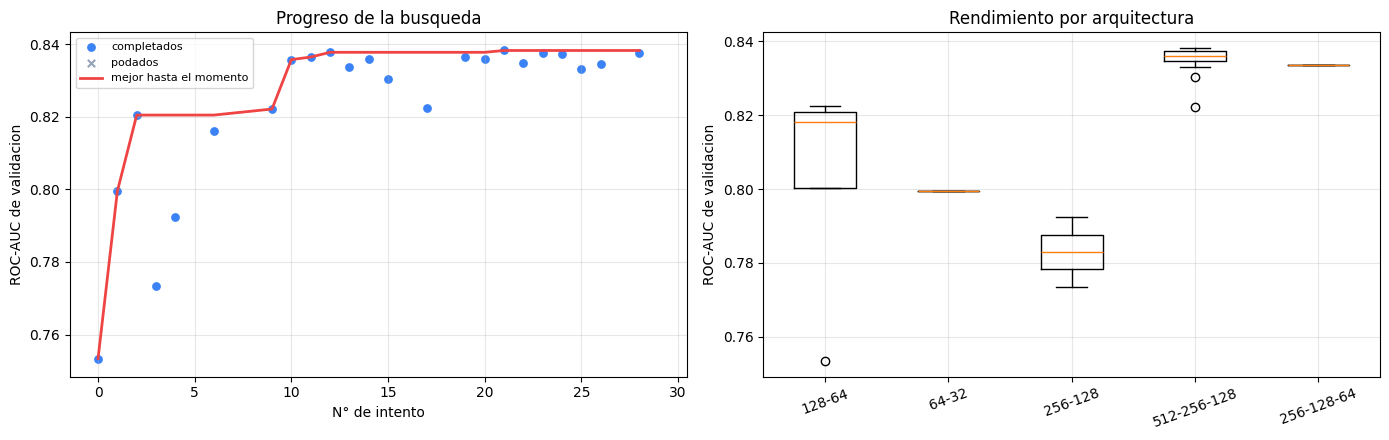

In [10]:
# --- Resultados del estudio -----------------------------------------------
completados = [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
podados = [t for t in estudio.trials if t.state == optuna.trial.TrialState.PRUNED]

print(f"Intentos completados: {len(completados)}   podados por el pruner: {len(podados)}")
if podados:
    print(f"El pruning evito terminar {len(podados)} configuraciones poco prometedoras.")

MEJORES = dict(estudio.best_params)
print(f"\nMejor ROC-AUC de validacion (sobre el {FRAC_BUSQUEDA:.0%}): {estudio.best_value:.4f}")
print("\nMejores hiperparametros encontrados:")
for k, v in MEJORES.items():
    print(f"   {k:<16} {v}")

# Ranking de los 10 mejores intentos
filas = [
    {"trial": t.number, "auc_val": t.value, **t.params}
    for t in sorted(completados, key=lambda t: t.value, reverse=True)[:10]
]
display(pd.DataFrame(filas).round(5))

# Importancia de cada hiperparametro
try:
    imp = optuna.importance.get_param_importances(estudio)
    print("\nImportancia relativa de cada hiperparametro:")
    for k, v in imp.items():
        print(f"   {k:<16} {'#' * int(round(v * 40)):<40} {v:.3f}")
except Exception as e:
    print(f"(no se pudo calcular la importancia: {e})")

# Historial de la busqueda
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
vals = [t.value for t in completados]
nums = [t.number for t in completados]
ax[0].scatter(nums, vals, s=28, color="#3b82f6", label="completados")
if podados:
    ax[0].scatter([t.number for t in podados], [0] * len(podados), s=28, marker="x",
                  color="#94a3b8", label="podados")
mejor_hasta = np.maximum.accumulate(vals) if vals else []
ax[0].plot(nums, mejor_hasta, color="#ef4444", lw=2, label="mejor hasta el momento")
ax[0].set_xlabel("N° de intento"); ax[0].set_ylabel("ROC-AUC de validacion")
ax[0].set_title("Progreso de la busqueda"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
if vals:
    ax[0].set_ylim(min(vals) - 0.005, max(vals) + 0.005)

arqs = {}
for t in completados:
    arqs.setdefault(t.params["arquitectura"], []).append(t.value)
nombres = list(arqs)
ax[1].boxplot([arqs[n] for n in nombres], labels=nombres)
ax[1].set_ylabel("ROC-AUC de validacion")
ax[1].set_title("Rendimiento por arquitectura")
ax[1].tick_params(axis="x", rotation=20)
ax[1].grid(alpha=0.3)
plt.tight_layout()
guardar_figura("optuna_busqueda.png")
plt.show()

---
# Celda 8 — Fase B.5: Modelos base con muestreo Bootstrap

Esta etapa corresponde al entrenamiento definitivo, **con el 100 % de los datos**.

## 8.1 Fundamento del muestreo Bootstrap

De un conjunto de N filas se extraen N observaciones **con reemplazo**. Estadísticamente, cada
muestra Bootstrap contiene alrededor del **63,2 %** de las filas originales distintas —algunas de
ellas repetidas— y deja fuera el 36,8 % restante, conjunto conocido como *Out-Of-Bag*.

El efecto buscado es que cada modelo base observe una distribución ligeramente distinta y, en
consecuencia, **cometa errores distintos**. Esa diversidad es la condición que permite que la
combinación de los modelos reduzca la varianza del predictor: si todos se equivocaran en las mismas
observaciones, promediarlos no aportaría mejora alguna.

## 8.2 Dos fuentes de diversidad, no una

El esquema de Bagging del código base introduce diversidad por una sola vía —el remuestreo de los
datos— y entrena los M modelos con una misma arquitectura y unos mismos hiperparámetros. Ese
planteamiento tiene una limitación conocida: modelos de idéntica configuración aprenden funciones
muy similares y sus errores quedan **fuertemente correlacionados**, de modo que el margen de mejora
del ensamble sobre el promedio simple resulta marginal. La meta-red de la Fase C, en ese escenario,
converge a pesos próximos a 1/M y su análisis carece de contenido interpretable.

Por ese motivo se incorpora una **segunda fuente de diversidad**: cada modelo base recibe una de
las **tres mejores configuraciones con arquitecturas distintas** del estudio de Optuna, en lugar de
replicar la ganadora. La función `configs_diversas()` recorre los intentos completados de mejor a
peor y retiene el primero de cada arquitectura.

Los tres modelos difieren por tanto en tres aspectos:

| Fuente de diversidad | Efecto |
|---|---|
| **Muestra Bootstrap** | Cada modelo ve ~63,2 % de las filas, con un 36,8 % *Out-Of-Bag* distinto |
| **Semilla** | Inicialización de pesos y orden de los lotes distintos |
| **Arquitectura e hiperparámetros** | Capacidad, regularización y tasa de aprendizaje distintas |

El remuestreo Bootstrap se conserva íntegro, de modo que el esquema sigue siendo Bagging; lo que se
amplía es el origen de la diversidad entre sus miembros.

> **Desviación documentada respecto del código base.** El código base entrena los M modelos con la
> configuración ganadora única. La modificación es deliberada y su objetivo es que la meta-red de la
> Fase C tenga algo sustantivo que ponderar: con miembros heterogéneos, los pesos aprendidos se
> vuelven interpretables y permiten contrastar la confianza asignada a cada modelo con su
> desempeño individual. Cabe advertir que la ganancia esperada en ROC-AUC sigue siendo modesta: la
> diversificación mejora las condiciones del ensamble, no garantiza un salto en la métrica.

## 8.3 Cantidad de modelos

El enunciado exige **2 a 3 modelos base para un grupo de un integrante**. Se entrenan **3**, el
máximo del rango.

Cada modelo persiste su mejor checkpoint en Google Drive por medio del mecanismo de Early Stopping,
junto con su propia configuración de arquitectura. Esto último es necesario para que el notebook 03
pueda reconstruir cada modelo sin ambigüedad, dado que ya no comparten estructura.

In [11]:
def muestra_bootstrap(X, y, semilla):
    """Extrae N muestras CON reemplazo y reporta la cobertura Out-Of-Bag."""
    g = torch.Generator().manual_seed(semilla)
    idx = torch.randint(0, len(X), (len(X),), generator=g)
    unicas = len(torch.unique(idx))
    return X[idx], y[idx], unicas / len(X)


M_MODELOS = 3
SEMILLAS = [SEED + 100 * i for i in range(M_MODELOS)]


def configs_diversas(estudio, cuantas):
    """Las mejores configuraciones del estudio con ARQUITECTURAS distintas.

    Recorre los intentos completados de mejor a peor y se queda con el primero
    de cada arquitectura. Si el estudio no ofrece suficientes arquitecturas
    distintas, completa con los siguientes mejores intentos aunque repitan, y
    si aun asi faltan, reutiliza los que haya.
    """
    completados = [t for t in estudio.trials
                   if t.state == optuna.trial.TrialState.COMPLETE]
    if not completados:
        raise RuntimeError("el estudio no tiene intentos completados")
    ordenados = sorted(completados, key=lambda t: t.value, reverse=True)

    elegidos, vistas = [], set()
    for t in ordenados:
        if t.params["arquitectura"] not in vistas:
            elegidos.append(t)
            vistas.add(t.params["arquitectura"])
        if len(elegidos) == cuantas:
            return elegidos
    for t in ordenados:
        if t not in elegidos:
            elegidos.append(t)
        if len(elegidos) == cuantas:
            return elegidos
    while len(elegidos) < cuantas:
        elegidos.append(ordenados[len(elegidos) % len(ordenados)])
    return elegidos


TRIALS_BASE = configs_diversas(estudio, M_MODELOS)
CONFIGS = [
    dict(ocultas=ARQUITECTURAS[t.params["arquitectura"]],
         dropout=t.params["dropout"], lr=t.params["lr"],
         weight_decay=t.params["weight_decay"], batch=t.params["batch"])
    for t in TRIALS_BASE
]

print("Configuraciones elegidas para los modelos base")
print("=" * 72)
print("Cada modelo recibe una de las mejores configuraciones DISTINTAS del")
print("estudio, en vez de repetir la ganadora: asi los miembros del ensamble")
print("difieren en estructura y no solo en su muestra Bootstrap.\n")
display(pd.DataFrame([
    {"modelo": f"base_{i}", "trial": t.number,
     "auc_busqueda": round(t.value, 5), **t.params}
    for i, t in enumerate(TRIALS_BASE, start=1)
]))

modelos, historiales, resumen = [], [], []
t_total = time.time()

for i, (semilla, cfg, trial) in enumerate(zip(SEMILLAS, CONFIGS, TRIALS_BASE),
                                          start=1):
    print(f"--- Modelo base {i}/{M_MODELOS}  "
          f"(arquitectura {trial.params['arquitectura']}, semilla {semilla}) ---")
    Xb, yb, cobertura = muestra_bootstrap(Xtr_t, ytr_t, semilla)
    print(f"    muestra Bootstrap: {len(Xb):,} filas, {cobertura:.1%} de filas unicas "
          f"({1-cobertura:.1%} Out-Of-Bag)")

    ckpt = CKPT_DIR / f"modelo_base_{i}.pt"
    modelo, hist = entrenar(
        Xb, yb, Xva_t, yva_t,
        epocas=60, paciencia=8, pos_weight=POS_WEIGHT,
        semilla=semilla, ckpt_path=ckpt, verbose=True, **cfg,
    )

    loss_va, auc_va = evaluar(modelo, Xva_t, yva_t)
    modelos.append(modelo)
    historiales.append(hist)
    resumen.append({
        "modelo": f"base_{i}", "arquitectura": trial.params["arquitectura"],
        "semilla": semilla, "cobertura_bootstrap": round(cobertura, 4),
        "mejor_epoca": hist["mejor_epoca"], "epocas_corridas": len(hist["loss_va"]),
        "loss_val": round(loss_va, 5), "auc_val": round(auc_va, 5),
        "minutos": round(hist["segundos"] / 60, 2),
    })
    print(f"    -> AUC de validacion {auc_va:.4f} | checkpoint en {ckpt.name} "
          f"| {hist['segundos']/60:.1f} min\n")
    del Xb, yb
    gc.collect()

print(f"=== {M_MODELOS} modelos entrenados en {(time.time()-t_total)/60:.1f} min ===")
df_resumen = pd.DataFrame(resumen)
display(df_resumen)
mem_report("tras entrenar los modelos base")


Configuraciones elegidas para los modelos base
Cada modelo recibe una de las mejores configuraciones DISTINTAS del
estudio, en vez de repetir la ganadora: asi los miembros del ensamble
difieren en estructura y no solo en su muestra Bootstrap.



,modelo,trial,auc_busqueda,arquitectura,dropout,lr,weight_decay,batch
0,base_1,21,0.83823,512-256-128,0.301905,0.002090,0.012432,512
1,base_2,13,0.83372,256-128-64,0.274492,0.004143,0.017999,2048
2,base_3,17,0.82243,128-64,0.439967,0.004964,0.007928,2048


--- Modelo base 1/3  (arquitectura 512-256-128, semilla 42) ---
    muestra Bootstrap: 699,999 filas, 63.2% de filas unicas (36.8% Out-Of-Bag)
    epoca   1 | loss_tr 0.5354 | loss_va 0.5247 | auc_va 0.8143 |    14s
    epoca   5 | loss_tr 0.4708 | loss_va 0.4868 | auc_va 0.8430 |    71s
    epoca  10 | loss_tr 0.4559 | loss_va 0.4796 | auc_va 0.8493 |   142s
    epoca  15 | loss_tr 0.4487 | loss_va 0.4755 | auc_va 0.8514 |   210s
    epoca  20 | loss_tr 0.4447 | loss_va 0.4755 | auc_va 0.8517 |   278s
    epoca  25 | loss_tr 0.4424 | loss_va 0.4743 | auc_va 0.8526 |   347s
    epoca  30 | loss_tr 0.4403 | loss_va 0.4742 | auc_va 0.8525 |   413s
    epoca  35 | loss_tr 0.4383 | loss_va 0.4732 | auc_va 0.8530 |   472s
    epoca  40 | loss_tr 0.4376 | loss_va 0.4736 | auc_va 0.8533 |   527s
    Early Stopping en la epoca 41 (mejor: epoca 33, loss_va 0.4731)
    -> AUC de validacion 0.8534 | checkpoint en modelo_base_1.pt | 9.0 min

--- Modelo base 2/3  (arquitectura 256-128-64, semilla 1

,modelo,arquitectura,semilla,cobertura_bootstrap,mejor_epoca,epocas_corridas,loss_val,auc_val,minutos
0,base_1,512-256-128,42,0.6323,33,41,0.47315,0.85341,8.98
1,base_2,256-128-64,142,0.6324,37,45,0.47710,0.84993,3.80
2,base_3,128-64,242,0.6315,35,43,0.50204,0.83332,1.82


[RAM] tras entrenar los modelos base     proceso:  1.22 GB | sistema: 20.90/34.16 GB (61%)


---
# Celda 9 — Fase B.6: Curvas de entrenamiento y aprendizaje

La rúbrica exige evidenciar un **entrenamiento estable y sin sobreajuste severo**. Los criterios de
lectura de cada gráfico son los siguientes:

- **Pérdida de entrenamiento frente a pérdida de validación.** Un descenso sostenido de la primera
  acompañado de un ascenso de la segunda indica sobreajuste. La marca vertical señala la época que
  Early Stopping seleccionó como óptima.
- **ROC-AUC de validación.** Debe crecer y estabilizarse en una meseta.
- **Brecha entre ambas curvas de pérdida.** Constituye la medida directa del grado de memorización
  del conjunto de entrenamiento.

Una precisión necesaria para interpretar correctamente los gráficos: la pérdida de entrenamiento se
calcula **con Dropout activo**, mientras que la de validación se evalúa con la red en modo
inferencia. Por esa razón, en las primeras épocas la pérdida de validación puede resultar *inferior*
a la de entrenamiento, sin que ello constituya una anomalía.

Las figuras se guardan en `reports/figures/curvas_modelos_base.png` y
`reports/figures/optuna_busqueda.png`.

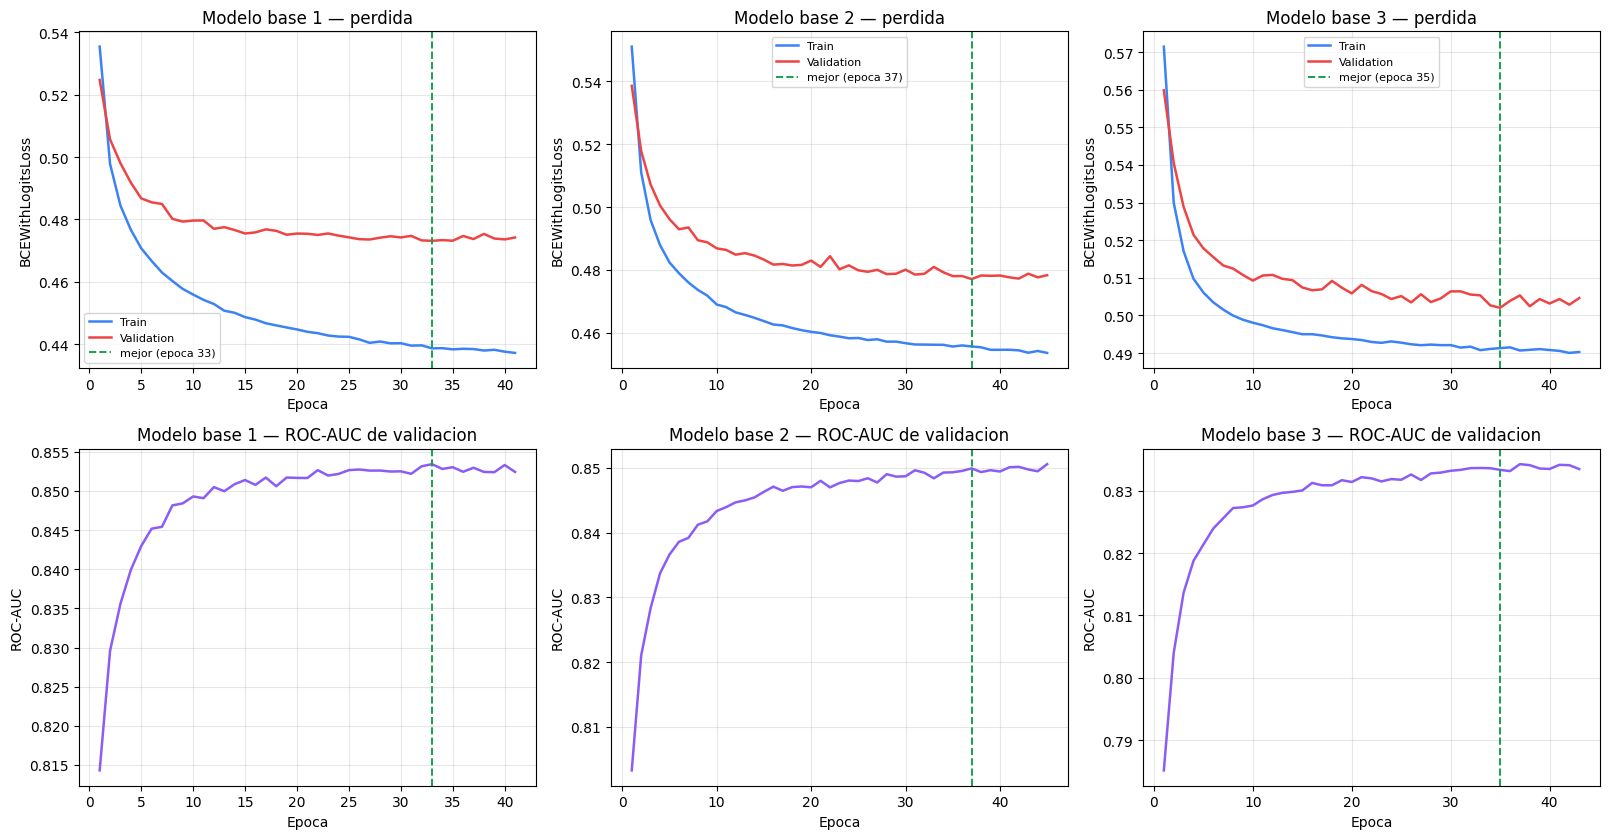

Brecha final entre Train y Validation (indicador de sobreajuste):
   modelo base 1: +0.0345
   modelo base 2: +0.0214
   modelo base 3: +0.0107


In [12]:
fig, axes = plt.subplots(2, M_MODELOS, figsize=(5.4 * M_MODELOS, 8.5))
if M_MODELOS == 1:
    axes = axes.reshape(2, 1)

for i, hist in enumerate(historiales):
    epocas = range(1, len(hist["loss_tr"]) + 1)

    ax = axes[0, i]
    ax.plot(epocas, hist["loss_tr"], label="Train", color="#3b82f6", lw=1.8)
    ax.plot(epocas, hist["loss_va"], label="Validation", color="#ef4444", lw=1.8)
    ax.axvline(hist["mejor_epoca"], color="#16a34a", ls="--", lw=1.4,
               label=f"mejor (epoca {hist['mejor_epoca']})")
    ax.set_title(f"Modelo base {i+1} — perdida")
    ax.set_xlabel("Epoca"); ax.set_ylabel("BCEWithLogitsLoss")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    ax = axes[1, i]
    ax.plot(epocas, hist["auc_va"], color="#8b5cf6", lw=1.8)
    ax.axvline(hist["mejor_epoca"], color="#16a34a", ls="--", lw=1.4)
    ax.set_title(f"Modelo base {i+1} — ROC-AUC de validacion")
    ax.set_xlabel("Epoca"); ax.set_ylabel("ROC-AUC")
    ax.grid(alpha=0.3)

plt.tight_layout()
guardar_figura("curvas_modelos_base.png")
plt.show()

print("Brecha final entre Train y Validation (indicador de sobreajuste):")
for i, h in enumerate(historiales, start=1):
    brecha = h["loss_va"][h["mejor_epoca"] - 1] - h["loss_tr"][h["mejor_epoca"] - 1]
    print(f"   modelo base {i}: {brecha:+.4f}")

In [ ]:
# --- Comparacion individual y guardado de los historiales -----------------
from sklearn.metrics import average_precision_score, f1_score

print(f"{'Modelo':<12}{'ROC-AUC':>10}{'PR-AUC':>10}{'F1':>9}{'Epocas':>9}{'Minutos':>9}")
print("-" * 59)
filas = []
for i, modelo in enumerate(modelos, start=1):
    modelo.eval()
    with torch.no_grad():
        logits = torch.cat([modelo(Xva_t[j:j + 8192]) for j in range(0, len(Xva_t), 8192)]).numpy()
    prob = 1 / (1 + np.exp(-logits))
    auc = roc_auc_score(y_val, prob)
    pr = average_precision_score(y_val, prob)
    f1 = f1_score(y_val, (prob >= 0.5).astype(int))
    h = historiales[i - 1]
    print(f"{'base_'+str(i):<12}{auc:>10.4f}{pr:>10.4f}{f1:>9.4f}"
          f"{len(h['loss_va']):>9}{h['segundos']/60:>9.1f}")
    filas.append({"modelo": f"base_{i}", "roc_auc": auc, "pr_auc": pr, "f1": f1})

# Promedio simple de los tres, como referencia de lo que el Stacking debe superar
with torch.no_grad():
    probs = []
    for modelo in modelos:
        modelo.eval()
        lg = torch.cat([modelo(Xva_t[j:j + 8192]) for j in range(0, len(Xva_t), 8192)]).numpy()
        probs.append(1 / (1 + np.exp(-lg)))
prom = np.mean(probs, axis=0)
auc_prom = roc_auc_score(y_val, prom)
print("-" * 59)
print(f"{'promedio':<12}{auc_prom:>10.4f}{average_precision_score(y_val, prom):>10.4f}"
      f"{f1_score(y_val, (prom >= 0.5).astype(int)):>9.4f}")

mejor_individual = max(f["roc_auc"] for f in filas)
print(f"\nMejor modelo individual: {mejor_individual:.4f} ROC-AUC")
print(f"Promedio simple de los {M_MODELOS}: {auc_prom:.4f} ({auc_prom-mejor_individual:+.4f})")
print("\nEse promedio simple es la referencia a superar: en el notebook 03, la")
print("meta-red del Stacking aprende PESOS para combinar los modelos en vez de")
print("promediarlos a ciegas, y debe quedar por encima de esta linea.")

# Historiales y metadatos para el notebook 03
np.savez(
    HIST_PATH,
    historiales=np.array(historiales, dtype=object),
    resumen=df_resumen.to_numpy(dtype=object),
    columnas_resumen=np.array(df_resumen.columns, dtype=object),
    # Una configuracion por modelo base, ya que no comparten arquitectura.
    configs=np.array(CONFIGS, dtype=object),
    arquitecturas=np.array([t.params["arquitectura"] for t in TRIALS_BASE],
                           dtype=object),
    trials_elegidos=np.array([t.number for t in TRIALS_BASE]),
    features=np.array(FEATURES, dtype=object),
)
print(f"\nHistoriales guardados en {HIST_PATH}")
print(f"Checkpoints disponibles en {CKPT_DIR}:")
for p in sorted(CKPT_DIR.glob('modelo_base_*.pt')):
    print(f"   {p.name:<24}{p.stat().st_size/1e3:>8.1f} KB")

---
# Resumen de la Fase B

> **Sección pendiente de redacción: requiere las cifras de la ejecución completa.** El contenido
> previsto abarca los cuatro puntos siguientes.
>
> 1. **Feature engineering.** Número de variables construidas que figuran entre las de mayor
>    correlación con la etiqueta, e identificación de la familia más informativa.
> 2. **Búsqueda con Optuna.** Cantidad de intentos podados, hiperparámetro de mayor importancia
>    según `optuna.importance`, y ahorro de tiempo atribuible a buscar sobre el 20 % de los datos
>    en lugar del 100 %.
> 3. **Modelos base.** Arquitectura asignada a cada uno y su ROC-AUC individual, estabilidad de las
>    curvas de entrenamiento y presencia o ausencia de sobreajuste. Interesa además contrastar el
>    AUC obtenido sobre el 20 % durante la búsqueda con el alcanzado al entrenar con el 100 %, y
>    verificar si el orden de mérito entre las tres configuraciones se mantiene al cambiar la
>    escala de datos.
> 4. **Línea base para el Stacking.** Desempeño del promedio simple de los tres modelos, que
>    constituye la referencia que la meta-red del notebook 03 debe superar, y dispersión entre los
>    tres AUC individuales, que indica cuánta diversidad efectiva se consiguió.

## Continuación

El notebook `03_Stacking_Ensemble_Final.ipynb` recupera los checkpoints desde `checkpoints/` —cada
uno con su propia configuración de arquitectura—, entrena la meta-red de Stacking con pesos
entrenables y evalúa el ensamble completo sobre el **conjunto de Test**, que hasta ese punto
permanece sin utilizar.